# e01 - Machine Learning Model Performance Evaluation

**Purpose.** One place that evaluates every model of the project with the same metrics. The experiment notebooks
(m01-m16) each answer one question; this notebook gathers their result tables, recomputes the per-crop metrics from the
saved out-of-fold predictions and tests whether the differences between models are real.

**Task.** Regression of the GAEZ v5 1 km suitability index (0-10,000) of 10 crops from the 14 physical drivers
(climate, soil, terrain) on 9,129 cells of Banten; the recommended-crop label derived from it is evaluated as a
classification task.

**Metrics.**

| metric | meaning | better |
| --- | --- | --- |
| R² | share of the variance of the index the model explains | higher, 1 = perfect |
| RMSE / MAE | typical error in index points (0-10,000) | lower |
| Spearman ρ | agreement of the ranking of cells (what a suitability map is used for) | higher |
| accuracy, balanced accuracy, macro-F1 | recommended-crop label; balanced/macro weigh the rare crops equally | higher |
| coverage, interval width | share of true values inside the 90 % prediction interval, and its width | coverage ≈ 0.90, narrower |
| Brier score | mean squared error of predicted probabilities | lower |

**Validation.** Three cross-validation schemes (5 folds): *random* K-fold, *block10* (10 km spatial blocks) and
*pixel* (cells grouped by the ~9 km GAEZ pixel they fall in). Pixel-grouped CV is the honest headline because random
folds leak neighbouring, nearly identical cells into training.

Runs in seconds: it only reads `results/*.csv` and `datasets/processed/experiments/m01_oof_pixel.parquet`.

*Duplicate copy kept in `evaluations/` so every model notebook can be found in one place. The maintained source is **`scripts/modeling/e01_ml_model_evaluation.ipynb`** — edit it there; this copy is regenerated from it, not edited directly.*

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable regardless of where this notebook is opened from (evaluations/, scripts/modeling/, or
# the project root), unlike a plain cwd-relative lookup.
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "environment.yml").exists())
HERE = PROJECT_ROOT / "scripts" / "modeling"
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import exp_lib as E

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
R = lambda name: pd.read_csv(E.RESULTS_DIR / f"{name}.csv")   # result tables written by the experiment notebooks
CROP_NAMES = {"rice": "Rice", "maize": "Maize", "cassava": "Cassava", "soybean": "Soybean", "oilpalm": "Oil palm",
              "rubber": "Rubber", "sugarcane": "Sugarcane", "coffee": "Coffee", "cacao": "Cacao", "coconut": "Coconut"}
MODEL_NAMES = {"et": "ExtraTrees", "xgb": "XGBoost", "hgb": "HistGB", "knn": "kNN", "ridge": "Ridge",
               "dummy": "Mean baseline", "logreg": "Logistic reg."}

## 1. Leaderboard over the three validation schemes (m01)

In [2]:
lb = R("m01_leaderboard").assign(model=lambda d: d["model"].map(MODEL_NAMES))
pix = R("m01_summary_pixel").assign(model=lambda d: d["model"].map(MODEL_NAMES))
board = lb.merge(pix[["model", "rmse", "spearman", "fit_s_per_5folds"]], on="model").sort_values("pixel", ascending=False)
board.columns = ["model", "R² random", "R² block10", "R² pixel", "optimism (random - pixel)", "RMSE pixel",
                 "Spearman pixel", "fit seconds (5 folds)"]
board.round(3)

,model,R² random,R² block10,R² pixel,optimism (random - pixel),RMSE pixel,Spearman pixel,fit seconds (5 folds)
0,ExtraTrees,0.914,0.819,0.820,0.094,873.10,0.902,5.079
1,XGBoost,0.885,0.808,0.809,0.076,899.60,0.896,0.958
2,HistGB,0.892,0.808,0.808,0.084,901.16,0.898,1.040
3,kNN,0.869,0.717,0.743,0.127,1046.90,0.864,0.099
4,Ridge,0.630,0.596,0.605,0.025,1309.20,0.776,0.100
5,Mean baseline,-0.000,-0.022,-0.008,0.008,2127.20,-0.111,0.003


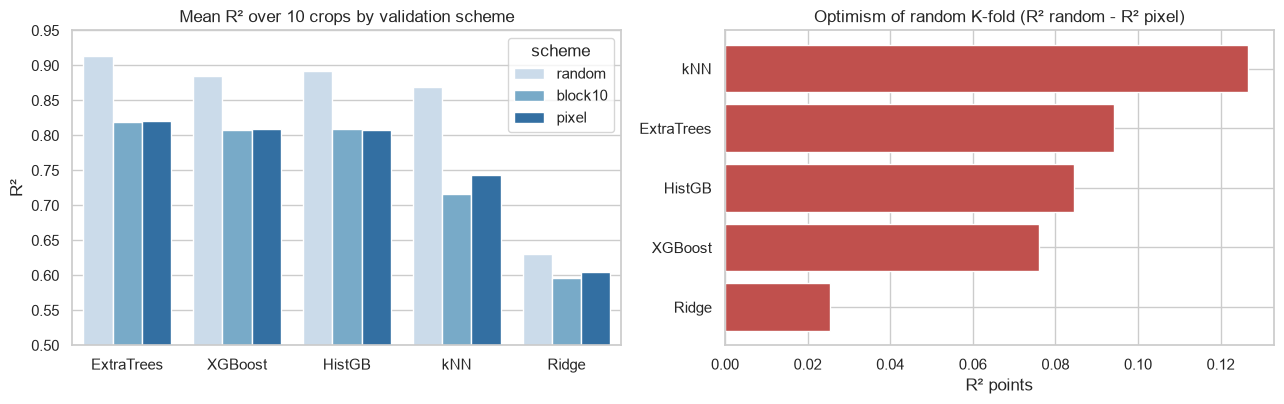

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
long = lb[lb["model"] != "Mean baseline"].melt(id_vars="model", value_vars=["random", "block10", "pixel"],
                                                var_name="scheme", value_name="R²")
sns.barplot(data=long, x="model", y="R²", hue="scheme", ax=ax[0], palette="Blues")
ax[0].set(ylim=(0.5, 0.95), title="Mean R² over 10 crops by validation scheme", xlabel="")
gap = lb[lb["model"] != "Mean baseline"].sort_values("leakage_gap")
ax[1].barh(gap["model"], gap["leakage_gap"], color="#c0504d")
ax[1].set(title="Optimism of random K-fold (R² random - R² pixel)", xlabel="R² points")
fig.tight_layout()
E.save_fig(fig, "e01_leaderboard");

**Reading.** The tree ensembles lead under every scheme, ExtraTrees first (R² 0.82 pixel-grouped). Random K-fold
inflates R² by 0.08-0.13 for the flexible models (kNN worst) but only 0.03 for ridge: the more a model can memorise
neighbours, the more random folds flatter it. The ranking of models does not change between schemes, only the level.

## 2. Stability over folds and repeats, and is the winner significantly better? (m01 raw runs)

In [4]:
raw = R("m01_baselines_raw").assign(model=lambda d: d["model"].map(MODEL_NAMES))
spread = (raw.groupby(["model", "scheme"])["r2"].agg(["mean", "std", "min", "max"]).unstack("scheme")
          .swaplevel(axis=1).sort_index(axis=1))
spread["pixel"].sort_values("mean", ascending=False).round(3)

,max,mean,min,std
model,,,,
ExtraTrees,0.854,0.820,0.755,0.033
XGBoost,0.848,0.809,0.741,0.036
HistGB,0.844,0.808,0.740,0.037
kNN,0.787,0.743,0.659,0.043
Ridge,0.665,0.605,0.465,0.056
Mean baseline,-0.002,-0.009,-0.014,0.004


In [5]:
# Paired test: the same crop and repeat are evaluated for every model, so compare models pair-wise per (crop, repeat).
p = raw[raw["scheme"] == "pixel"].pivot_table(index=["target", "repeat"], columns="model", values="r2")
rows = []
for other in ["XGBoost", "HistGB", "kNN", "Ridge"]:
    d = p["ExtraTrees"] - p[other]
    w = stats.wilcoxon(p["ExtraTrees"], p[other])
    rows.append({"ExtraTrees vs": other, "pairs": len(d), "mean ΔR²": d.mean(), "ExtraTrees wins": f"{(d > 0).sum()}/{len(d)}",
                 "Wilcoxon p": w.pvalue})
sig = pd.DataFrame(rows)
E.save_table(sig, "e01_significance")
sig.round({"mean ΔR²": 4})

,ExtraTrees vs,pairs,mean ΔR²,ExtraTrees wins,Wilcoxon p
0,XGBoost,20,0.0110,19/20,0.000004
1,HistGB,20,0.0120,20/20,0.000002
2,kNN,20,0.0772,20/20,0.000002
3,Ridge,20,0.2150,20/20,0.000002


## 3. Per-crop performance recomputed from the out-of-fold predictions

`m01_oof_pixel.parquet` holds the pixel-grouped out-of-fold prediction of every cell for ExtraTrees, XGBoost and
HistGB, i.e. every cell predicted by a model that never saw its GAEZ pixel.

In [6]:
df = E.load_table()
oof = df[["grid_id", "lon", "lat", "landcover_majority"] + E.gaez_cols()].merge(
    pd.read_parquet(E.OOF_DIR / "m01_oof_pixel.parquet"), on="grid_id", validate="1:1")
rows = []
for m in ["et", "xgb", "hgb"]:
    for c in E.CROPS:
        y, yhat = oof[E.target_col(c)].to_numpy(), oof[f"{m}__{c}"].to_numpy()
        rows.append({"model": MODEL_NAMES[m], "crop": CROP_NAMES[c], **E.regression_metrics(y, yhat),
                     "mean index": y.mean(), "std index": y.std()})
per_crop = pd.DataFrame(rows)
E.save_table(per_crop, "e01_per_crop_metrics")
per_crop[per_crop["model"] == "ExtraTrees"].drop(columns="model").set_index("crop").round(3)

,r2,rmse,mae,spearman,mean index,std index
crop,,,,,,
Rice,0.854,939.383,577.545,0.913,3050.377,2461.561
Maize,0.811,437.994,271.054,0.903,1335.229,1007.313
Cassava,0.842,1091.342,682.877,0.912,3922.939,2742.000
Soybean,0.776,650.070,359.558,0.892,1763.880,1373.604
Oil palm,0.833,1133.524,727.116,0.911,4407.874,2773.621
Rubber,0.761,446.928,297.687,0.865,2278.393,913.270
Sugarcane,0.850,681.995,437.205,0.912,2346.246,1761.366
Coffee,0.838,1121.296,708.649,0.911,3864.075,2788.496
Cacao,0.814,907.067,585.868,0.900,3225.434,2103.486


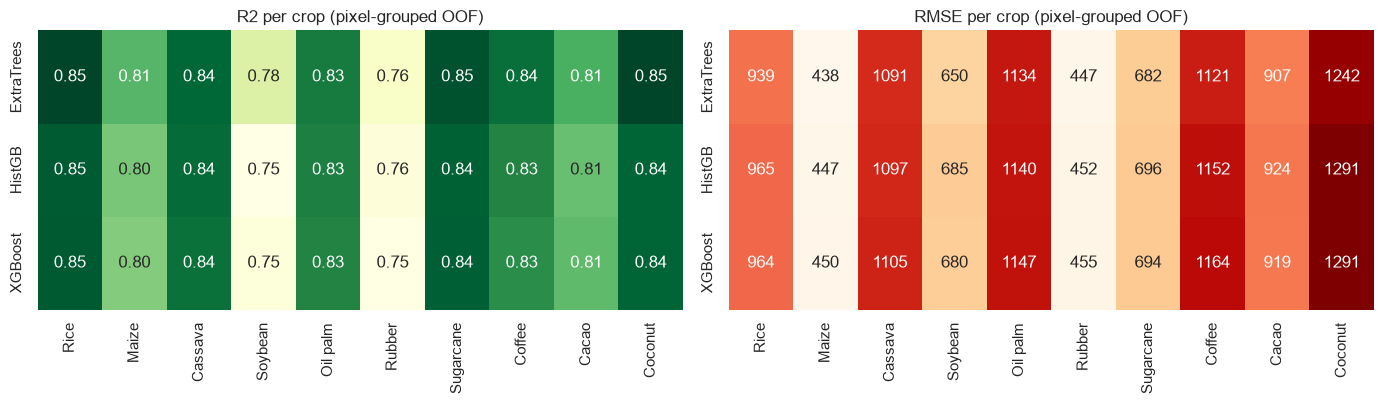

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, metric, cmap in [(ax[0], "r2", "YlGn"), (ax[1], "rmse", "OrRd")]:
    h = per_crop.pivot(index="model", columns="crop", values=metric)[list(CROP_NAMES.values())]
    sns.heatmap(h, annot=True, fmt=".2f" if metric == "r2" else ".0f", cmap=cmap, ax=a, cbar=False)
    a.set(title=f"{metric.upper()} per crop (pixel-grouped OOF)", xlabel="", ylabel="")
fig.tight_layout()
E.save_fig(fig, "e01_per_crop_heatmap");

## 4. Errors of the best model: observed vs predicted, residuals by land cover and in space

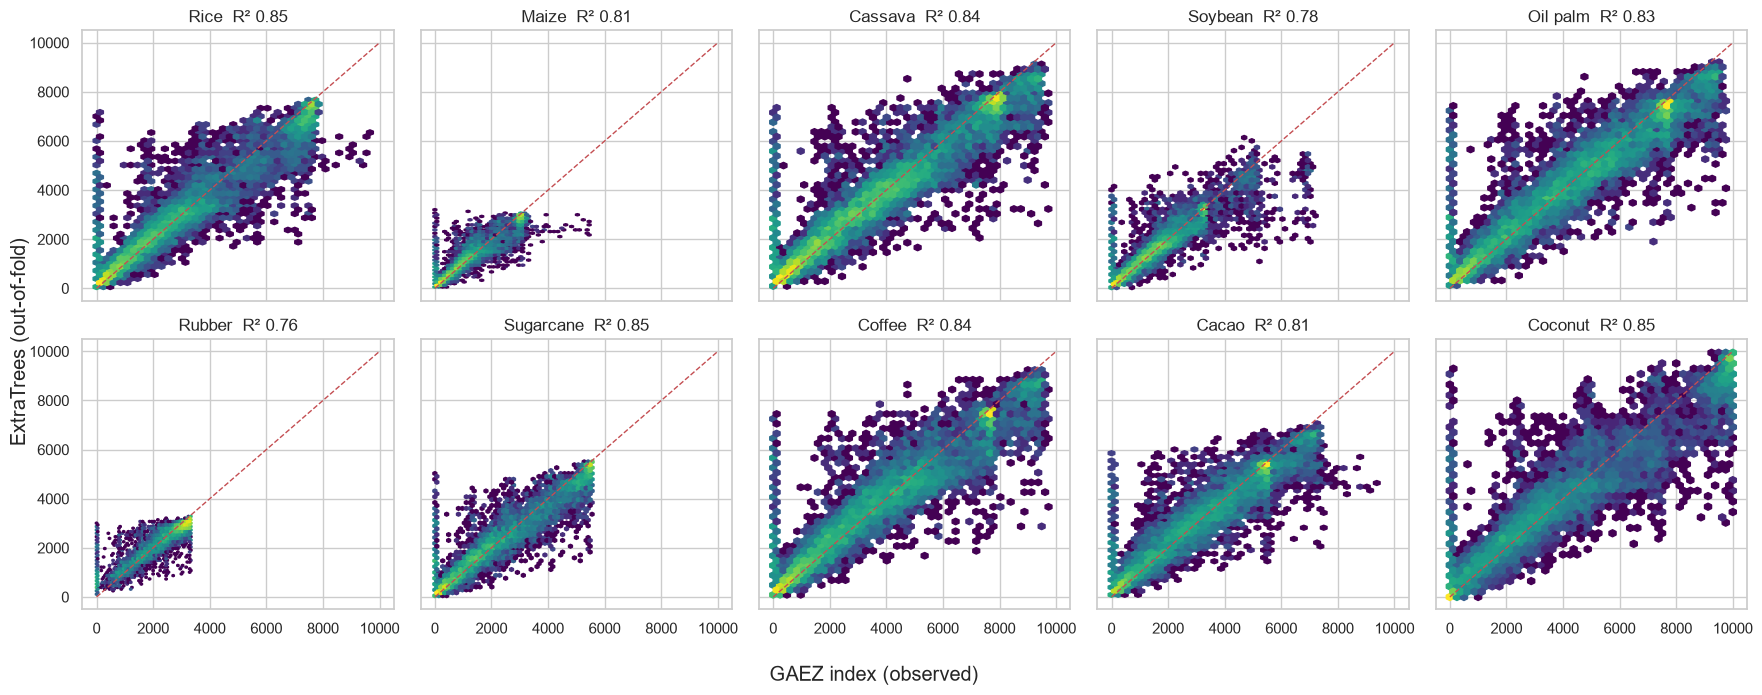

In [8]:
LC = {10: "Tree cover", 30: "Grassland", 40: "Cropland", 50: "Built-up", 60: "Bare", 80: "Water", 90: "Wetland", 95: "Mangroves"}
fig, ax = plt.subplots(2, 5, figsize=(18, 7), sharex=True, sharey=True)
for a, c in zip(ax.ravel(), E.CROPS):
    y, yhat = oof[E.target_col(c)], oof[f"et__{c}"]
    a.hexbin(y, yhat, gridsize=40, mincnt=1, cmap="viridis", bins="log")
    a.plot([0, 10000], [0, 10000], "r--", lw=1)
    a.set_title(f"{CROP_NAMES[c]}  R² {E.regression_metrics(y.to_numpy(), yhat.to_numpy())['r2']:.2f}")
fig.supxlabel("GAEZ index (observed)"); fig.supylabel("ExtraTrees (out-of-fold)")
fig.tight_layout()
E.save_fig(fig, "e01_observed_vs_predicted");

In [9]:
res = pd.DataFrame({c: oof[f"et__{c}"] - oof[E.target_col(c)] for c in E.CROPS})
res["land cover"] = oof["landcover_majority"].map(LC)
by_lc = (res.melt(id_vars="land cover", var_name="crop", value_name="residual")
         .assign(abs_err=lambda d: d["residual"].abs())
         .groupby("land cover").agg(cells=("residual", lambda s: len(s) // len(E.CROPS)), bias=("residual", "mean"),
                                    MAE=("abs_err", "mean"))
         .sort_values("MAE", ascending=False))
E.save_table(by_lc.reset_index(), "e01_error_by_landcover")
by_lc.round(1)

,cells,bias,MAE
land cover,,,
Bare,2,-1587.6,1587.6
Built-up,772,908.7,1561.0
Grassland,76,-597.3,1014.8
Water,163,-41.7,779.2
Wetland,12,-532.4,532.6
Cropland,1282,-254.3,505.6
Mangroves,6,-351.9,451.5
Tree cover,6816,-38.0,424.7


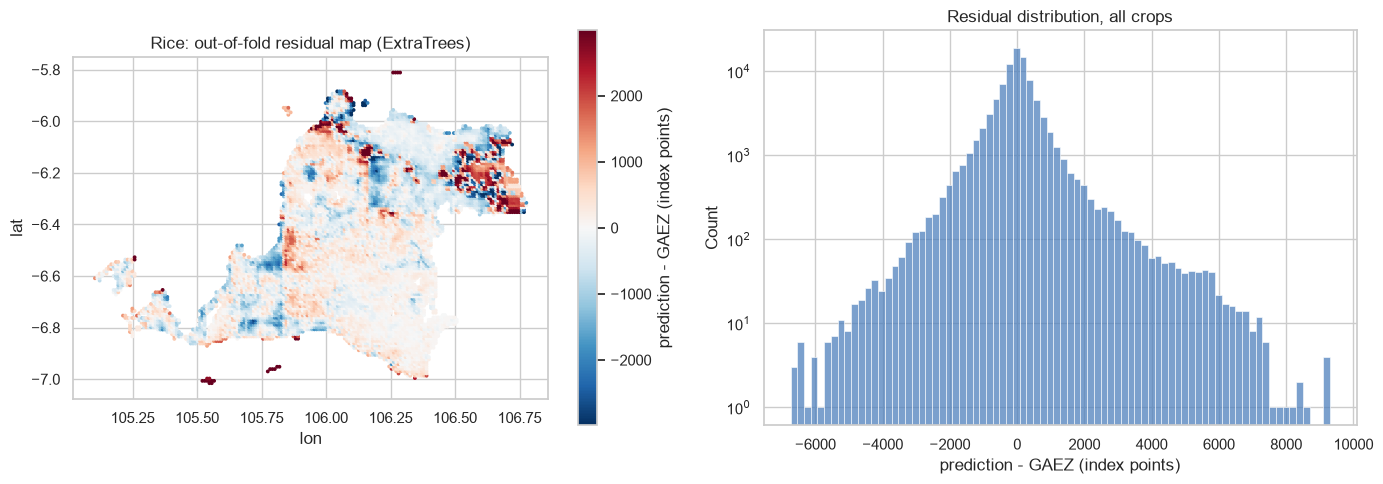

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
r = res["rice"]
lim = np.nanpercentile(r.abs(), 98)
sc = ax[0].scatter(oof["lon"], oof["lat"], c=r, s=3, cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.colorbar(sc, ax=ax[0], label="prediction - GAEZ (index points)")
ax[0].set(title="Rice: out-of-fold residual map (ExtraTrees)", aspect="equal", xlabel="lon", ylabel="lat")
sns.histplot(res[E.CROPS].melt()["value"], bins=80, ax=ax[1], color="#4f81bd")
ax[1].set(title="Residual distribution, all crops", xlabel="prediction - GAEZ (index points)", yscale="log")
fig.tight_layout()
E.save_fig(fig, "e01_residuals");

## 5. What drives the score: validation block size and feature groups (m02, m03)

In [11]:
bs = R("m02_blocksize_summary").rename(columns={"Unnamed: 0": "scheme"})
fs = R("m03_featuresets_summary")
display(bs[["scheme", "pixel_overlap", "et", "hgb", "ridge"]].round(3))
fs.sort_values("hgb", ascending=False).round(3)

,scheme,pixel_overlap,et,hgb,ridge
0,random,0.999,0.914,0.892,0.630
1,block5,0.986,0.846,0.833,0.618
2,block10,0.846,0.819,0.808,0.596
3,block20,0.543,0.781,0.775,0.509
4,block40,0.360,0.690,0.717,0.299
5,pixel,0.000,0.820,0.808,0.605


,feature_set,ridge,hgb,n_features
12,everything - soil,0.715,0.873,18
11,everything - climate,0.708,0.870,20
10,everything,0.728,0.870,25
8,base + land cover,0.724,0.852,23
15,everything - coords,0.724,0.852,23
9,base + coordinates,0.620,0.835,16
14,everything - landcover,0.620,0.835,16
13,everything - terrain,0.644,0.826,23
6,climate + terrain,0.585,0.810,7
7,climate + soil + terrain (base),0.605,0.808,14


## 6. Beyond the 14 drivers: Sentinel-2, deep learning, ensembles and data size (m12, m14)

,setting,family,r2,spearman,rmse
8,"Fusion, patch + drivers","neural networks, image patches",0.868,0.929,741.81
7,"ExtraTrees, drivers + Sentinel-2","trees, per-cell statistics",0.865,0.928,755.00
6,"HistGB, drivers + Sentinel-2","trees, per-cell statistics",0.856,0.923,779.90
5,"ExtraTrees, 14 drivers","trees, per-cell statistics",0.819,0.901,876.43
4,"HistGB, 14 drivers","trees, per-cell statistics",0.805,0.896,909.72
3,"MLP, 14 drivers","neural networks, image patches",0.789,0.887,948.85
2,"CNN, image patch","neural networks, image patches",0.764,0.868,1012.00
1,"ExtraTrees, Sentinel-2 only","trees, per-cell statistics",0.723,0.845,1097.50
0,"HistGB, Sentinel-2 only","trees, per-cell statistics",0.708,0.835,1128.20


,ensemble,members,r2,rmse,mae,spearman
3,et + hgb,2,0.821,869.70,542.85,0.903
4,et + xgb,2,0.821,871.41,545.76,0.903
0,et,1,0.820,873.10,547.64,0.902
6,et + hgb + xgb,3,0.820,872.77,545.01,0.903
7,trees + knn,4,0.816,881.33,553.17,0.901
5,hgb + xgb,2,0.812,891.12,555.10,0.899
2,xgb,1,0.809,899.60,562.84,0.896
1,hgb,1,0.808,901.16,559.25,0.898
8,everything,5,0.805,910.60,593.64,0.896


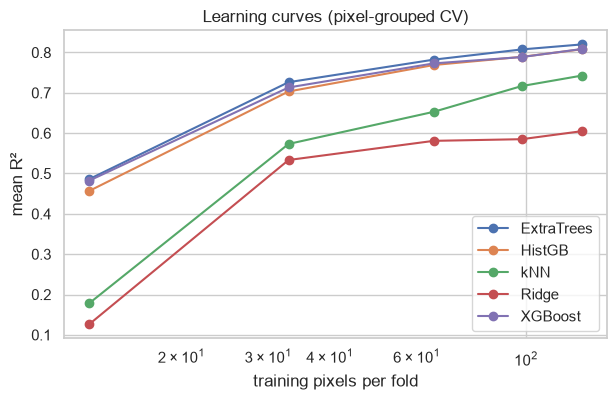

In [12]:
display(R("m14_summary").sort_values("r2", ascending=False).round(3))
display(R("m12_ensembles").sort_values("r2", ascending=False).round(3))
lc = R("m12_learning_curves").set_index("training pixels per fold")
ax = lc.rename(columns=MODEL_NAMES).plot(marker="o", logx=True, figsize=(7, 4), title="Learning curves (pixel-grouped CV)")
ax.set(ylabel="mean R²")
E.save_fig(ax.figure, "e01_learning_curves");

## 7. Classification of the recommended crop (m05)

In [13]:
cls = R("m05_leaderboard").assign(model=lambda d: d["model"].replace(MODEL_NAMES))
cls_pix = cls[cls["scheme"] == "pixel"].pivot_table(index="model", columns="target", values=["accuracy", "balanced_acc", "macro_f1"])
display(cls_pix.round(3))
R("m05_binary_by_crop_pixel").round(3)

accuracy        balanced_acc        macro_f1       
target          thresh    top       thresh    top   thresh    top
model                                                            
ExtraTrees       0.845  0.824        0.511  0.518    0.508  0.530
HistGB           0.855  0.827        0.471  0.499    0.480  0.506
Logistic reg.    0.725  0.684        0.520  0.551    0.377  0.422
Mean baseline    0.558  0.470        0.143  0.125    0.102  0.080
XGBoost          0.855  0.822        0.433  0.442    0.461  0.482
hgb + rule       0.792  0.718        0.442  0.370    0.418  0.282
kNN              0.807  0.787        0.469  0.442    0.489  0.466
xgb + rule       0.798  0.728        0.404  0.352    0.366  0.297

,target,prevalence,et,hgb,logreg,xgb
0,cacao,0.274,0.894,0.902,0.880,0.889
1,cassava,0.335,0.892,0.901,0.864,0.899
2,coconut,0.317,0.886,0.892,0.841,0.880
3,coffee,0.339,0.885,0.891,0.846,0.884
4,oilpalm,0.431,0.892,0.898,0.850,0.897
5,rice,0.239,0.916,0.918,0.881,0.902
6,sugarcane,0.130,0.897,0.917,0.908,0.866


**Reading.** Accuracy (0.82-0.86) looks good mainly because "not recommended" is the majority class (the dummy
already reaches 0.47-0.56). Balanced accuracy and macro-F1 near 0.5 show that the rare crops are often confused with
each other: the label is an argmax over ten close indices, so small regression errors flip it. The per-crop
binary task "suitable / not suitable" (index ≥ 5,000) is far easier: balanced accuracy 0.84-0.92 for every crop.

## 8. Uncertainty: are the 90 % intervals and the probabilities honest? (m15)

coverage               mean width                 
                                         min   mean    max        min     mean     max
inputs               interval                                                         
drivers              adaptive          0.897  0.899  0.900     1023.8  2025.30  2783.0
                     constant width    0.897  0.898  0.899     1209.0  2342.14  3273.5
drivers + Sentinel-2 adaptive          0.898  0.899  0.900      932.7  1852.37  2572.0
                     constant width    0.898  0.899  0.899     1121.2  2124.55  2963.4

,inputs,land cover,cells,"coverage, adaptive","coverage, constant width","mean width, adaptive"
0,drivers,Tree cover,6816,0.907,0.949,1684.1
1,drivers,Cropland,1282,0.947,0.913,2396.6
2,drivers,Built-up,772,0.751,0.479,4147.2
3,drivers,Water,163,0.887,0.829,2618.8
4,drivers,Grassland,76,0.908,0.708,3353.5
5,drivers,Wetland,12,1.000,0.892,2709.3
6,drivers,Mangroves,6,1.000,0.983,2618.9
7,drivers,Bare / sparse,2,0.550,0.550,2972.6
8,drivers + Sentinel-2,Tree cover,6816,0.900,0.938,1606.8
9,drivers + Sentinel-2,Cropland,1282,0.925,0.920,1770.2


,inputs,accuracy of the most likely label,accuracy of the point-estimate label,Brier score (labels),mean probability of the true label,"Brier score (suitable, per crop)"
0,drivers,0.819,0.814,0.252,0.745,0.048
1,drivers + Sentinel-2,0.828,0.823,0.245,0.758,0.042


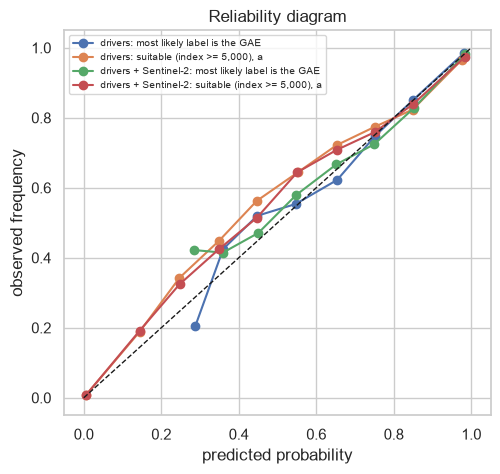

In [14]:
cov = R("m15_coverage")
display(cov.groupby(["inputs", "interval"])[["coverage", "mean width"]].agg(["min", "mean", "max"]).round(3))
display(R("m15_coverage_by_landcover").round(3))
display(R("m15_probability_scores").round(3))
rel = R("m15_reliability")
fig, ax = plt.subplots(figsize=(5.5, 5))
for (inp, ev), g in rel.groupby(["inputs", "event"]):
    ax.plot(g["predicted"], g["observed"], marker="o", label=f"{inp}: {ev[:28]}")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="predicted probability", ylabel="observed frequency", title="Reliability diagram")
ax.legend(fontsize=7)
E.save_fig(fig, "e01_reliability");

## 9. Scorecard

In [15]:
big = by_lc[by_lc["cells"] >= 50]
et_crop = per_crop[per_crop["model"] == "ExtraTrees"].set_index("crop")["r2"]
card = pd.DataFrame([
    ["Best model, 14 drivers (pixel CV)", "ExtraTrees", "R² 0.820, RMSE 873, ρ 0.902"],
    ["Optimism of random K-fold", "ExtraTrees", f"+{lb.set_index('model').loc['ExtraTrees', 'leakage_gap']:.3f} R²"],
    ["Hardest / easiest crop", "ExtraTrees",
     f"{et_crop.idxmin()} (R² {et_crop.min():.2f}) / {et_crop.idxmax()} (R² {et_crop.max():.2f})"],
    ["Largest error by land cover (≥ 50 cells)", "ExtraTrees", f"{big.index[0]} (MAE {big['MAE'].iloc[0]:.0f}, bias {big['bias'].iloc[0]:+.0f})"],
    ["Best model overall", "Fusion CNN + drivers", "R² 0.869 (drivers + Sentinel-2)"],
    ["Recommended-crop label (pixel CV)", "HistGB / ExtraTrees", "accuracy 0.83-0.86, macro-F1 ≈ 0.5"],
    ["90 % intervals", "adaptive conformal", "coverage 0.897-0.901 on all crops"],
    ["With vs without Spark MLlib", "see e02", "same accuracy, slower at this data size"],
], columns=["aspect", "model", "result"])
E.save_table(card, "e01_scorecard")
card

,aspect,model,result
0,"Best model, 14 drivers (pixel CV)",ExtraTrees,"R² 0.820, RMSE 873, ρ 0.902"
1,Optimism of random K-fold,ExtraTrees,+0.094 R²
2,Hardest / easiest crop,ExtraTrees,Rubber (R² 0.76) / Coconut (R² 0.85)
3,Largest error by land cover (≥ 50 cells),ExtraTrees,"Built-up (MAE 1561, bias +909)"
4,Best model overall,Fusion CNN + drivers,R² 0.869 (drivers + Sentinel-2)
5,Recommended-crop label (pixel CV),HistGB / ExtraTrees,"accuracy 0.83-0.86, macro-F1 ≈ 0.5"
6,90 % intervals,adaptive conformal,coverage 0.897-0.901 on all crops
7,With vs without Spark MLlib,see e02,"same accuracy, slower at this data size"
